# Ejercicio 4 · Mejoras: terminar hacia el 90 % sin pendiente y entrenar con parada y checkpoints

El ejercicio 4 (1,5 puntos) propone tres ideas y pide especificar con detalle la mejora y su lógica.
Este notebook implementa y mide dos de ellas, las más baratas de medir con el protocolo ya montado y
ligadas a lo que se dijo en clase (`docs/teoria/10_hoja_de_ruta_practica.md` §8.1):

- **Idea B.** No dejar volumen pendiente y consumir aproximadamente el 90 % de la duración de la orden,
  con una calibración de las recompensas que dé resultados estables (D-4.1).
- **Idea C.** Parar el entrenamiento según el aprendizaje, guardar los pesos para no perder un buen
  entrenamiento y poder recuperarlo (D-4.2).
- **Idea A** (precio con información de mercado) queda planteada al final, sin implementar.

**Punto de partida.** La configuración final del ej. 2 (D-2.2…D-2.7): estado `[T, V]`, recompensa de
seguimiento con cierre `TrackingCierre` con recorte c = 20, γ = 0,9, buffer de 10.000, aprender cada 8
pasos y copiar la red objetivo cada 1.000, red de 32 neuronas, 300 episodios. Cada experimento cambia
un solo factor sobre esa base.

**Cómo leerlo.** Los entrenamientos se lanzan con `scripts/ej4_ideaB.py` y `scripts/ej4_ideaC.py`
(21 y 3 entrenamientos) y quedan en `results/`. Este notebook solo lee esos resultados, recalcula
las tablas y dibuja las figuras, así que se ejecuta en uno o dos minutos. El código nuevo está en
`notebooks/common/ej4.py`; `protocol.py` y `rewards.py` no se modifican, porque sus hashes forman
parte de las auditorías de los ejercicios 1-3.

| Bloque | Cambio respecto al ej. 2 | Decisión |
|---|---|---|
| Recompensa | El plan TWAP acaba en 0,9·N y lo pendiente se penaliza al final con −k·pendiente/n | D-4.1 |
| Bucle | `ej4.Trainer`: checkpoint completo, parada por objetivo, estancamiento o tope, reanudación exacta | D-4.2 |
| Exploración (solo C) | ε por mejora del ej. 3, variante d (E0 fijo, escala log) | D-3.4 |

In [1]:
import sys, json, inspect, textwrap
from pathlib import Path
from IPython.display import display, Markdown

ROOT = Path.cwd() if (Path.cwd() / "notebooks" / "common").is_dir() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "notebooks"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from common import data as dt, protocol as pr, plots as pl, ej4
from common.env import BestExecutionEnv
from common.agents import DDQNAgent

torch.set_num_threads(1)
pd.set_option("display.precision", 3)
%matplotlib inline

def mostrar_codigo(*objetos):
    # Muestra el código real importado de common/, sin redefinirlo
    for o in objetos:
        fuente = textwrap.dedent(inspect.getsource(o))
        archivo = Path(inspect.getfile(o)).relative_to(ROOT).as_posix()
        display(Markdown(f"**`{o.__qualname__}` · `{archivo}`**\n\n```python\n{fuente.rstrip()}\n```"))

DATA = dt.load("REP")
train, test = DATA["train"], DATA["test"]
GRID = pr.make_grid(train, n_days=3, seed=0)        # rejilla fija de evaluación (D-0.3)
GRID_TEST = pr.make_grid(test, n_days=3, seed=0)
print(len(GRID), "episodios de evaluación en train ·", len(GRID_TEST), "en test · banda aceptada", ej4.BAND)

27 episodios de evaluación en train · 27 en test · banda aceptada (0.8, 0.95)


## 1. Idea B · Qué se pide y cómo se traduce en recompensa

**Lo que pide el enunciado.** Añadir recompensas para que (1) no quede volumen pendiente y (2) se
consuma aproximadamente el 90 % de la duración de la orden, dejando margen, con una calibración que
asegure la estabilidad. En clase se habló de terminar «más o menos» en el 90 %, en un rango del 80 al
95 % («te doy un poco de tiempo de más»), y de que el objetivo es sencillo pero hay que aprender a
calibrar. **Tomamos la banda 80-95 % del tiempo con el 100 % del volumen** (`ej4.BAND`).

**Decisión (opción B-1 de la hoja de ruta, plan comprimido).** Mantener la recompensa de seguimiento
del ej. 2, pero contra un TWAP que acaba en 0,9·N:

$$\mathrm{plan}_t = \min\big(n,\ t\,n / (0{,}9\,N)\big), \qquad
r_t = -\min(|e_t - \mathrm{plan}_t|,\ c)/c, \qquad r_{\text{final}} \mathrel{+}= -k\cdot \text{pendiente}/n .$$

Se conserva el **cierre** del ej. 2: si la orden se completa antes de N, se cobran los pasos que faltan
como si el agente siguiera quieto. Sin él, en el ej. 2 el agente aprendía a acabar pronto para dejar
de pagar penalizaciones (D-2.6). El esqueleto inicial de este notebook usaba `Tracking` sin cierre y se
ha corregido.

Para medir sin trampas se añaden dos piezas: la política de referencia `TWAPh`, que es el TWAP
determinista que acaba en h·N (con h = 1 coincide exactamente con `TWAPAgent`, y hay un test que lo
comprueba), y el error de seguimiento frente al plan comprimido (`max_err_h`). El `max_err` de
`protocol` mide frente al plan de N pasos y aquí penalizaría precisamente lo que se pide.

In [2]:
mostrar_codigo(ej4.make_reward, ej4.TWAPh, ej4.metrics_h)

**`make_reward` · `notebooks/common/ej4.py`**

```python
def make_reward(horizon=0.9, k=0.0, gamma=0.9, clip=20.0):
    """Seguimiento con cierre (ej. 2) sobre el plan que acaba en horizon·N, más -k·pendiente/n al final."""
    return rw.TrackingCierre(gamma=gamma, clip=clip, horizon=horizon, pending_penalty=k)
```

**`TWAPh` · `notebooks/common/ej4.py`**

```python
class TWAPh:
    """TWAP determinista que acaba en h·N: compra si lo ejecutado no supera el plan comprimido.
    Con h = 1 es exactamente TWAPAgent. Sirve de referencia para la idea B."""
    epsilon, gamma, _trainable = 0.0, 1.0, False

    def __init__(self, horizon=0.9, env=None):
        self.horizon, self.env = horizon, env

    def act(self, s):
        T, V = s[0], s[1]
        v_plan = 1.0 - min(1.0, (1.0 - T) / self.horizon)     # volumen restante que marca el plan
        return int(V >= v_plan - 1e-9)

    def set_trainable(self, train=False):
        pass
```

**`metrics_h` · `notebooks/common/ej4.py`**

```python
def metrics_h(env, horizon):
    """Métricas extra frente al plan comprimido y frente a la banda de finalización."""
    N, n = env.episode_bins, env.vol_care
    e = pr.trajectory(env)
    plan = np.minimum(n, np.arange(1, N + 1) * n / (horizon * N))
    err = np.abs(e - plan)
    t_fin = len(env.vol_hist) / N
    return {"max_err_h": float(err.max()), "mean_err_h": float(err.mean()),
            "in_band": bool(env.exec_vol >= n and BAND[0] <= t_fin <= BAND[1])}
```

## 2. Calibrar antes de entrenar: cuánto pesa cada término

Antes de elegir k medimos el tamaño de cada término con políticas fijas sobre la rejilla de train
(`ej4.calibration`). «Seguimiento» es la suma de recompensas de paso más el cierre; «terminal(k)» es el
término −k·pendiente/n, que se cobra una sola vez. La columna del peso final da γ^(0,1·N): cuánto pesa,
visto desde el 90 % del episodio, algo que ocurre al final.

In [3]:
CAL = ej4.calibration(train, GRID, gammas=(0.9, 0.995), ks=(1.0, 10.0, 50.0))
CAL[["seguimiento", "seguimiento_desc", "pendiente_frac", "t_fin", "peso_final_desde_0.9N",
     "terminal_k1", "terminal_k10", "terminal_k50"]].round(3)

seguimiento  seguimiento_desc  \
política                          gamma                                  
TWAP 0.9·N (objetivo)             0.900       -9.553            -0.254   
                                  0.995       -9.595            -3.819   
TWAP 1·N (ej. 2)                  0.900      -54.510            -0.229   
                                  0.995      -54.510           -12.221   
TWAP 0.9·N que deja el último 5 % 0.900      -15.760            -0.254   
                                  0.995      -15.760            -4.364   
TWAP 0,8·N (acaba pronto)         0.900      -65.492            -0.313   
                                  0.995      -71.264           -20.638   
todo al principio                 0.900      -48.130            -4.029   
                                  0.995     -190.835          -151.906   

                                         pendiente_frac  t_fin  \
política                          gamma                          
TWAP 0.9·N (objetivo)             0.900           0.000  0.883   
                                  0.995           0.000  0.883   
TWAP 1·N (ej. 2)                  0.900           0.000  0.981   
                                  0.995           0.000  0.981   
TWAP 0.9·N que deja el último 5 % 0.900           0.041  1.000   
                                  0.995           0.041  1.000   
TWAP 0,8·N (acaba pronto)         0.900           0.000  0.786   
                                  0.995           0.000  0.786   
todo al principio                 0.900           0.000  0.100   
                                  0.995           0.000  0.100   

                                         peso_final_desde_0.9N  terminal_k1  \
política                          gamma                                       
TWAP 0.9·N (objetivo)             0.900                  0.007        0.000   
                                  0.995                  0.779        0.000   
TWAP 1·N (ej. 2)                  0.900                  0.007        0.000   
                                  0.995                  0.779        0.000   
TWAP 0.9·N que deja el último 5 % 0.900                  0.007       -0.041   
                                  0.995                  0.779       -0.041   
TWAP 0,8·N (acaba pronto)         0.900                  0.007        0.000   
                                  0.995                  0.779        0.000   
todo al principio                 0.900                  0.007        0.000   
                                  0.995                  0.779        0.000   

                                         terminal_k10  terminal_k50  
política                          gamma                              
TWAP 0.9·N (objetivo)             0.900         0.000         0.000  
                                  0.995         0.000         0.000  
TWAP 1·N (ej. 2)                  0.900         0.000         0.000  
                                  0.995         0.000         0.000  
TWAP 0.9·N que deja el último 5 % 0.900        -0.415        -2.073  
                                  0.995        -0.415        -2.073  
TWAP 0,8·N (acaba pronto)         0.900         0.000         0.000  
                                  0.995         0.000         0.000  
todo al principio                 0.900         0.000         0.000  
                                  0.995         0.000         0.000

In [4]:
c09 = CAL.xs(0.9, level="gamma")
obj, deja = c09.iloc[0], c09.iloc[2]
display(Markdown(
    f"Dejar el último 5 % sin comprar empeora el seguimiento de {obj.seguimiento:.2f} a {deja.seguimiento:.2f} "
    f"(**{obj.seguimiento - deja.seguimiento:.2f}** por episodio), mientras que el término terminal añade "
    f"{deja.terminal_k1:.3f} con k = 1, {deja.terminal_k10:.2f} con k = 10 y {deja.terminal_k50:.2f} con k = 50. "
    f"Con γ = 0,9, lo que pasa al final del episodio pesa {obj['peso_final_desde_0.9N']:.3f} visto desde el 90 % "
    f"de la duración; con γ = 0,995 pesa {CAL.xs(0.995, level='gamma').iloc[0]['peso_final_desde_0.9N']:.2f}."))

Dejar el último 5 % sin comprar empeora el seguimiento de -9.55 a -15.76 (**6.21** por episodio), mientras que el término terminal añade -0.041 con k = 1, -0.41 con k = 10 y -2.07 con k = 50. Con γ = 0,9, lo que pasa al final del episodio pesa 0.007 visto desde el 90 % de la duración; con γ = 0,995 pesa 0.78.

**Lectura.** Con el plan comprimido, el seguimiento ya castiga el volumen pendiente: a partir de 0,9·N
el plan vale n, de modo que cada paso con títulos por comprar cuesta en proporción a lo que falta, y lo
hace en cada paso, no solo al final. El término terminal es mucho menor salvo con k muy grande. La
hipótesis previa, por tanto, es que **k actuará como red de seguridad y apenas cambiará el
comportamiento**. La teoría (`10_hoja_de_ruta_practica.md` §6.4, G3) recomienda subir γ hacia 0,995 cuando
hay un término terminal; con γ = 0,9 ese término no se ve desde donde se decide. Lo medimos en vez de
suponerlo.

## 3. Barrido de un factor cada vez

Siete configuraciones con tres semillas, 300 episodios cada una y ε lineal de 1 a 0,05, como en el ej. 2
(`scripts/ej4_ideaB.py`, unos 20 minutos con 4 procesos). La selección se hace **solo con train**:

- referencia del ej. 2: plan a N (h = 1), k = 0;
- plan a 0,9·N con k ∈ {0, 1, 10, 50} y γ = 0,9;
- plan a 0,9·N con γ = 0,995 (G3) y k ∈ {0, 10}.

In [5]:
B = pr.load_df("ej4_ideaB")
REF = {"TWAP 0,9·N (referencia)": ej4.evaluate(ej4.TWAPh(0.9), train, GRID, ej4.make_reward(0.9), 0.9),
       "TWAP 1·N": ej4.evaluate(ej4.TWAPh(1.0), train, GRID, ej4.make_reward(0.9), 0.9)}
TAB_B = B.groupby(["horizon", "k", "gamma"]).apply(ej4.summary, include_groups=False)
TAB_B.index = [f"DDQN h={h:g} · k={k:g} · γ={g:g}" for h, k, g in TAB_B.index]
TAB_B = pd.concat([TAB_B, pd.DataFrame({n: ej4.summary(r) for n, r in REF.items()}).T])
TAB_B.round(3)

,completas,pendientes,t_fin,t_fin_std,t_fin_min,t_fin_max,en_banda,max_err_h,mean_err_h,slip_vs_twap_bps
DDQN h=0.9 · k=0 · γ=0.9,1.000,0.000,0.887,0.005,0.878,0.893,1.000,0.889,0.242,-0.510
DDQN h=0.9 · k=0 · γ=0.995,1.000,0.000,0.864,0.029,0.822,0.900,1.000,2.618,0.581,-0.645
DDQN h=0.9 · k=1 · γ=0.9,1.000,0.000,0.887,0.005,0.875,0.895,1.000,0.889,0.247,-0.485
DDQN h=0.9 · k=10 · γ=0.9,1.000,0.000,0.888,0.005,0.878,0.897,1.000,0.889,0.243,-0.487
DDQN h=0.9 · k=10 · γ=0.995,0.333,1.852,0.959,0.059,0.875,1.000,0.333,3.303,0.969,-0.668
DDQN h=0.9 · k=50 · γ=0.9,1.000,0.000,0.888,0.005,0.878,0.895,1.000,0.889,0.243,-0.508
DDQN h=1 · k=0 · γ=0.9,1.000,0.000,0.988,0.006,0.975,0.997,0.000,0.900,0.271,-0.011
"TWAP 0,9·N (referencia)",1.000,0.000,0.883,0.005,0.872,0.890,1.000,0.889,0.384,-0.659
TWAP 1·N,1.000,0.000,0.981,0.005,0.970,0.988,0.000,4.977,2.115,0.000


In [6]:
# Estabilidad entre semillas: error máx. medio frente al plan de 0,9·N y fracción en banda, por semilla
SEM = B.groupby(["horizon", "k", "gamma", "seed"]).agg(max_err_h=("max_err_h", "mean"), en_banda=("in_band", "mean"),
                                                      completas=("completed", "mean")).unstack("seed")
SEM.round(2)

max_err_h             en_banda           completas       \
seed                       0     1     2        0    1    2         0    1   
horizon k    gamma                                                           
0.9     0.0  0.900      0.89  0.89  0.89      1.0  1.0  1.0       1.0  1.0   
             0.995      2.85  0.92  4.08      1.0  1.0  1.0       1.0  1.0   
        1.0  0.900      0.89  0.89  0.89      1.0  1.0  1.0       1.0  1.0   
        10.0 0.900      0.89  0.89  0.89      1.0  1.0  1.0       1.0  1.0   
             0.995      1.35  4.83  3.73      1.0  0.0  0.0       1.0  0.0   
        50.0 0.900      0.89  0.89  0.89      1.0  1.0  1.0       1.0  1.0   
1.0     0.0  0.900      0.90  0.90  0.90      0.0  0.0  0.0       1.0  1.0   

                         
seed                  2  
horizon k    gamma       
0.9     0.0  0.900  1.0  
             0.995  1.0  
        1.0  0.900  1.0  
        10.0 0.900  1.0  
             0.995  0.0  
        50.0 0.900  1.0  
1.0     0.0  0.900  1.0

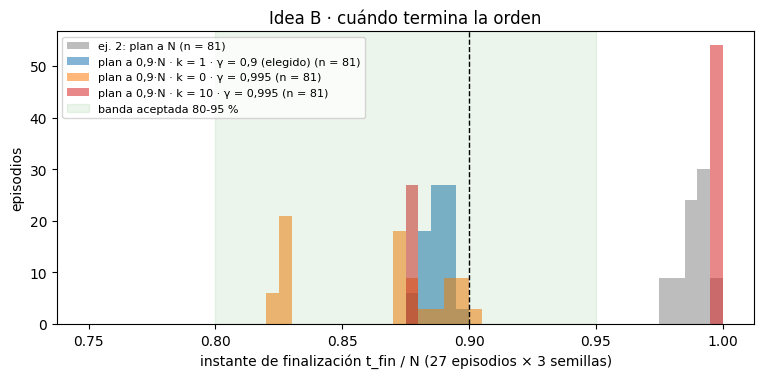

In [7]:
fig, ax = plt.subplots(figsize=(9, 3.8))
sel = [((1.0, 0.0, 0.9), "ej. 2: plan a N", "#888888"), ((0.9, 1.0, 0.9), "plan a 0,9·N · k = 1 · γ = 0,9 (elegido)", "#1f77b4"),
       ((0.9, 0.0, 0.995), "plan a 0,9·N · k = 0 · γ = 0,995", "#ff7f0e"), ((0.9, 10.0, 0.995), "plan a 0,9·N · k = 10 · γ = 0,995", "#d62728")]
bins = np.linspace(0.75, 1.0, 51)
for (h, k, g), lab, col in sel:
    t = B[(B.horizon == h) & (B.k == k) & (B.gamma == g)].t_fin
    ax.hist(t, bins=bins, alpha=0.55, color=col, label=f"{lab} (n = {len(t)})")
ax.axvspan(*ej4.BAND, color="green", alpha=0.08, label="banda aceptada 80-95 %")
ax.axvline(0.9, color="k", ls="--", lw=1)
ax.set_xlabel("instante de finalización t_fin / N (27 episodios × 3 semillas)"); ax.set_ylabel("episodios")
ax.set_title("Idea B · cuándo termina la orden"); ax.legend(fontsize=8, loc="upper left")
pl.save(fig, "ej4_ideaB_tfin")

In [8]:
best = B[(B.horizon == 0.9) & (B.k == 1.0) & (B.gamma == 0.9)]
g995 = B[(B.horizon == 0.9) & (B.gamma == 0.995)]
display(Markdown(
    f"Con el plan a 0,9·N y γ = 0,9 las tres semillas completan {best.completed.mean():.0%} de las órdenes, "
    f"terminan en t/N = {best.t_fin.mean():.3f} ± {best.t_fin.std():.3f} (rango {best.t_fin.min():.3f}-{best.t_fin.max():.3f}) "
    f"y quedan dentro de la banda en el {best.in_band.mean():.0%} de los episodios. Su error máximo frente al plan "
    f"({best.max_err_h.mean():.3f}) coincide con el del TWAP de referencia ({REF['TWAP 0,9·N (referencia)'].max_err_h.mean():.3f}). "
    f"Con γ = 0,995 la finalización media cae en {g995.t_fin.mean():.3f}, pero completa solo el {g995.completed.mean():.0%} "
    f"y el error sube a {g995.max_err_h.mean():.2f} títulos."))

Con el plan a 0,9·N y γ = 0,9 las tres semillas completan 100% de las órdenes, terminan en t/N = 0.887 ± 0.005 (rango 0.875-0.895) y quedan dentro de la banda en el 100% de los episodios. Su error máximo frente al plan (0.889) coincide con el del TWAP de referencia (0.889). Con γ = 0,995 la finalización media cae en 0.911, pero completa solo el 67% y el error sube a 2.96 títulos.

**Lectura del barrido.**

- **Comprimir el plan resuelve los dos objetivos a la vez.** El agente pasa de terminar en ≈ 0,99·N
  (ej. 2) a ≈ 0,89·N, sin volumen pendiente, con una dispersión de unas milésimas entre episodios e
  idéntica en las tres semillas: es la estabilidad que pide el enunciado.
- **k no cambia nada con γ = 0,9.** Con k = 0, 1, 10 o 50 los resultados son iguales dentro del ruido,
  como anticipaba la calibración: el seguimiento ya hace el trabajo y el término terminal solo actuaría
  si el agente se quedara atrás.
- **Subir γ empeora.** Con γ = 0,995 los valores Q crecen (horizonte ≈ 200 pasos), la diferencia entre
  esperar y comprar se diluye y aparecen semillas inestables, que dejan órdenes a medias o se alejan
  del plan. Coincide con el barrido de γ del ej. 2 (D-2.3). La recomendación teórica de γ alto vale
  para recompensas **terminales y dispersas**; aquí la señal es densa y local, y γ = 0,9 basta.

**Decisión D-4.1.** Plan a 0,9·N, **k = 1** y γ = 0,9. Todos los k son equivalentes en train; k = 1
deja explícita la penalización del pendiente que pide el enunciado sin cambiar el comportamiento.

## 4. Un episodio de ejemplo y la comprobación en test

Una ejecución del modelo elegido (semilla 0) en el episodio más largo de la rejilla: la curva de volumen
acumulado llega a 1 hacia el 90 % del eje.

N = 600, n = 75: termina en t/N = 0.895, pendiente = 0


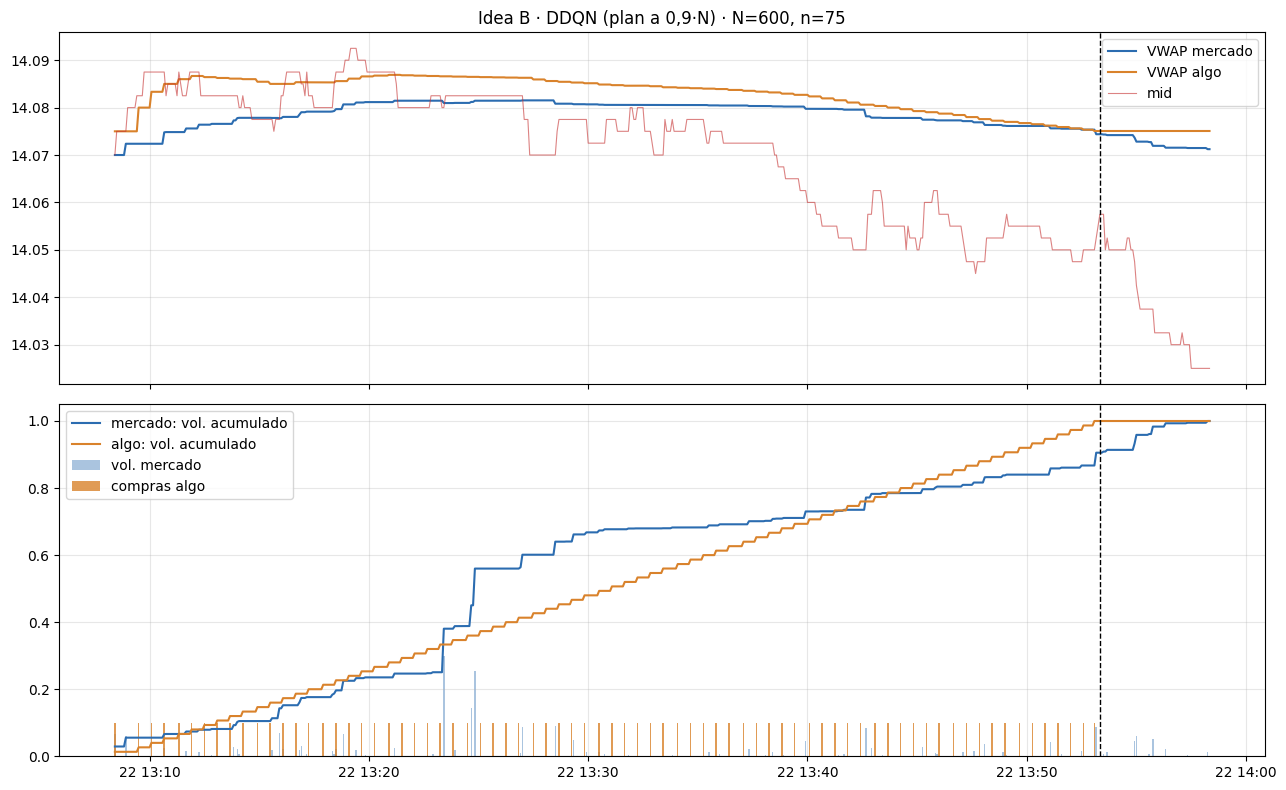

In [9]:
R_B = ej4.make_reward(0.9, 1.0, 0.9)
def carga_b(seed, data):
    a = DDQNAgent(BestExecutionEnv(data, reward=R_B, seed=seed), seed=seed, gamma=0.9, hidden_neurons=32)
    a.load(pr.RESULTS / ej4.RUNS_B / f"{ej4.run_name(0.9, 1.0, 0.9, seed)}.pt")
    return a
agent_b = carga_b(0, train)
cfg = max(GRID, key=lambda c: (c["n_bins"], c["vol_care"]))
env = BestExecutionEnv(train, reward=R_B, seed=0)
agent_b.env = env; agent_b.set_trainable(False)
pr.run_episode(env, agent_b, cfg)
print(f"N = {env.episode_bins}, n = {env.vol_care}: termina en t/N = {len(env.vol_hist) / env.episode_bins:.3f}, "
      f"pendiente = {env.vol_care - env.exec_vol}")
fig = pl.plot_results(env, title=f"Idea B · DDQN (plan a 0,9·N) · N={env.episode_bins}, n={env.vol_care}")
mkt = env.stats_df()[1]
for a in fig.axes:   # línea vertical en el 90 % de la duración
    a.axvline(mkt.index[int(0.9 * len(mkt)) - 1], color="k", ls="--", lw=1)
pl.save(fig, "ej4_ideaB_episodio")

**Test, una sola vez.** Con la configuración ya cerrada en train, se evalúan los tres modelos guardados
en la rejilla de test (27 episodios de días no vistos). Los valores se leen de `results/ej4_ideaB_test.csv`
y se pueden regenerar con la celda siguiente.

In [10]:
f = pr.RESULTS / "ej4_ideaB_test.csv"
if not f.exists():
    rows = [ej4.evaluate(carga_b(s, test), test, GRID_TEST, R_B, 0.9).assign(policy="DDQN", seed=s) for s in (0, 1, 2)]
    rows.append(ej4.evaluate(ej4.TWAPh(0.9), test, GRID_TEST, R_B, 0.9).assign(policy="TWAP 0.9N", seed=-1))
    pr.save_df(pd.concat(rows), "ej4_ideaB_test")
BT = pr.load_df("ej4_ideaB_test")
BT.groupby(["policy", "seed"]).apply(ej4.summary, include_groups=False).round(3)

completas  pendientes  t_fin  t_fin_std  t_fin_min  t_fin_max  \
policy    seed                                                                  
DDQN       0          1.0         0.0  0.889      0.005      0.880      0.895   
           1          1.0         0.0  0.887      0.005      0.878      0.893   
           2          1.0         0.0  0.884      0.004      0.875      0.890   
TWAP 0.9N -1          1.0         0.0  0.883      0.005      0.872      0.890   

                en_banda  max_err_h  mean_err_h  slip_vs_twap_bps  
policy    seed                                                     
DDQN       0         1.0      0.889       0.247             0.721  
           1         1.0      0.889       0.241             0.771  
           2         1.0      0.889       0.253             0.749  
TWAP 0.9N -1         1.0      0.889       0.384             0.829

En test se mantiene el comportamiento: las tres semillas completan todas las órdenes y terminan dentro
de la banda, con el mismo error máximo que el TWAP comprimido. El slippage frente al TWAP de N pasos
solo refleja que se compra antes, no una ventaja de precio: con estado `[T, V]` el agente no ve el
mercado.

## 5. Idea C · Parada por aprendizaje, checkpoints y recuperación

**Lo que pide el enunciado.** Condiciones de parada basadas en el aprendizaje, guardar los pesos cada
cierto tiempo para no perder un buen entrenamiento y poder recuperarlo. En clase se pidió guardar por si
hay *catastrophic forgetting* o el agente se atasca, para recuperar y darle otra oportunidad.

**Por qué un bucle propio.** `protocol.train` ya guardaba `*_best.pt` y `*_last.pt` y tenía paciencia,
pero al revisarlo para reanudar aparecieron cinco problemas:
1. `best` se reiniciaba en cada llamada, así que al reanudar se podía sobrescribir `*_best.pt` con un
   modelo peor y la paciencia empezaba de cero;
2. `learn_counter` volvía a 0 y desplazaba las fases de aprendizaje y de copia de la red objetivo;
3. el checkpoint no guardaba el buffer, los generadores aleatorios (agente, entorno, torch) ni el
   estado del plan de ε;
4. el objetivo se daba por cumplido con una sola evaluación;
5. una mejora menor que `min_delta` no se guardaba como mejor modelo.

`ej4.Trainer` mantiene el mismo bucle, pero con todo el estado en un objeto que se guarda entero.

**Reglas de parada** (la primera que se cumpla):
- (a) **objetivo**: error ≤ 1,5 títulos en 2 evaluaciones seguidas;
- (b) **estancamiento**: 6 evaluaciones (150 episodios) sin mejorar 0,05 títulos; son más que las 2 que
  usa el ε por mejora para volver a explorar, para no cortar esa reexploración;
- (c) **tope** de 600 episodios.

Se evalúa cada 25 episodios en la rejilla fija, sin explorar. En cada evaluación se guarda `*_last.pt` y,
si mejora, `*_best.pt`.

In [11]:
mostrar_codigo(ej4.Trainer.save, ej4.Trainer.load, ej4.Trainer._evaluate)

**`Trainer.save` · `notebooks/common/ej4.py`**

```python
def save(self, path, **extra):
    import copy
    import torch
    a = self.agent
    state = {k: copy.deepcopy(getattr(self, k)) for k in self._STATE}
    state.update(buffer=list(a.buffer), agent_rng=a.rng.bit_generator.state,
                 env_rng=self.env.rng.bit_generator.state, torch_rng=torch.get_rng_state())
    a.save(path, trainer=state, **extra)
```

**`Trainer.load` · `notebooks/common/ej4.py`**

```python
def load(self, path):
    import torch
    ckpt = self.agent.load(path)
    st = ckpt["trainer"]
    for k in self._STATE:
        setattr(self, k, st[k])
    self.agent.buffer.clear()
    self.agent.buffer.extend(st["buffer"])
    self.agent.rng.bit_generator.state = st["agent_rng"]
    self.env.rng.bit_generator.state = st["env_rng"]
    torch.set_rng_state(st["torch_rng"])
    return ckpt
```

**`Trainer._evaluate` · `notebooks/common/ej4.py`**

```python
def _evaluate(self):
    metric, df = greedy_metric(self.agent, self.data, self.grid, self.reward, self.horizon)
    self.exploration.on_eval(self.agent, metric)
    self.agent.set_trainable(True)
    improved = metric < self.best_kept                      # cualquier mejora -> *_best.pt
    if metric < self.best - self.min_delta:                 # mejora suficiente -> reinicia paciencia
        self.best, self.since_best = metric, 0
    else:
        self.since_best += 1
    self.hits = self.hits + 1 if self.target is not None and metric <= self.target else 0
    row = {"episode": self.episode, "max_err_h": metric, "completed": df.completed.mean(),
           "t_fin": df.t_fin.mean(), "epsilon": self.agent.epsilon, "saved_best": improved}
    if improved:
        self.best_kept = metric
    self.ev_rows.append(row)
    if self.target is not None and self.hits >= self.target_hits:
        self.stop_reason = f"objetivo: {self.target_hits} evaluaciones seguidas con error ≤ {self.target}"
    elif self.patience and self.since_best >= self.patience:
        self.stop_reason = f"estancamiento: {self.patience} evaluaciones sin mejorar {self.min_delta}"
    elif self.episode >= self.max_episodes:
        self.stop_reason = f"tope de {self.max_episodes} episodios"
    if self.checkpoint:
        if improved:
            self.save(f"{self.checkpoint}_best.pt", episode=self.episode, metric=metric)
        self.save(f"{self.checkpoint}_last.pt", episode=self.episode, metric=metric)
```

In [12]:
C_SUM = json.loads((pr.RESULTS / "ej4_ideaC.json").read_text(encoding="utf-8"))
C_EV, C_TR = pr.load_df("ej4_ideaC_evals"), pr.load_df("ej4_ideaC_train")
C_FX = pr.load_df("ej4_ideaC_evals_fijo")   # mismas semillas, 300 episodios sin parada
print(f"Configuración: {C_SUM['config']} · E* (TWAP a 0,9·N) = {C_SUM['e_star']:.3f} · objetivo ≤ {C_SUM['target']}")
pd.DataFrame(C_SUM["runs"]).set_index("seed")

Configuración: {'horizon': 0.9, 'k': 1.0, 'gamma': 0.9} · E* (TWAP a 0,9·N) = 0.889 · objetivo ≤ 1.5


,stop,episodes,seconds
seed,,,
0,objetivo: 2 evaluaciones seguidas con error ≤ 1.5,125,117.893
1,objetivo: 2 evaluaciones seguidas con error ≤ 1.5,125,119.019
2,objetivo: 2 evaluaciones seguidas con error ≤ 1.5,150,134.235


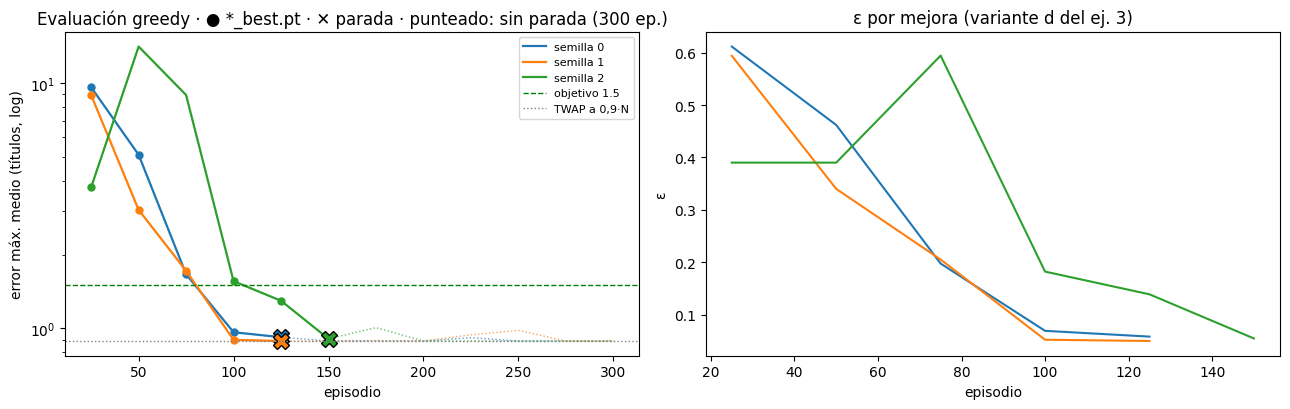

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
cols = {0: "#1f77b4", 1: "#ff7f0e", 2: "#2ca02c"}
for s, g in C_FX.groupby("seed"):
    axes[0].plot(g.episode, g.max_err_h, ":", color=cols[s], lw=1, alpha=0.7)
for s, g in C_EV.groupby("seed"):
    axes[0].plot(g.episode, g.max_err_h, "-", color=cols[s], lw=1.6, label=f"semilla {s}")
    sb = g[g.saved_best]
    axes[0].plot(sb.episode, sb.max_err_h, "o", color=cols[s], ms=5)
    axes[0].plot(g.episode.iloc[-1], g.max_err_h.iloc[-1], "X", color=cols[s], ms=11, mec="k")
    axes[1].plot(g.episode, g.epsilon, "-", color=cols[s], label=f"semilla {s}")
axes[0].axhline(C_SUM["target"], color="green", ls="--", lw=1, label=f"objetivo {C_SUM['target']}")
axes[0].axhline(C_SUM["e_star"], color="gray", ls=":", lw=1, label="TWAP a 0,9·N")
axes[0].set_yscale("log"); axes[0].set_xlabel("episodio"); axes[0].set_ylabel("error máx. medio (títulos, log)")
axes[0].set_title("Evaluación greedy · ● *_best.pt · ✕ parada · punteado: sin parada (300 ep.)"); axes[0].legend(fontsize=8)
axes[1].set_xlabel("episodio"); axes[1].set_ylabel("ε"); axes[1].set_title("ε por mejora (variante d del ej. 3)")
fig.tight_layout(); pl.save(fig, "ej4_ideaC_training")

**Mejor frente a último.** Con parada por objetivo, el entrenamiento se detiene justo después de una
mejora, así que el último checkpoint y el mejor suelen coincidir. Para ver qué protege el mejor
checkpoint, las mismas semillas se entrenan también 300 episodios sin parada (curvas punteadas) y se
evalúan sus dos checkpoints.

In [14]:
C_FIN = pr.load_df("ej4_ideaC_final")
C_FIN.groupby(["seed", "checkpoint", "ckpt_episode"]).apply(ej4.summary, include_groups=False).round(3)

completas  pendientes  t_fin  t_fin_std  \
seed checkpoint        ckpt_episode                                            
0    best              125                 1.0         0.0  0.886      0.004   
     last              125                 1.0         0.0  0.886      0.004   
     sin parada · best 150                 1.0         0.0  0.886      0.005   
     sin parada · last 300                 1.0         0.0  0.887      0.005   
1    best              125                 1.0         0.0  0.886      0.005   
     last              125                 1.0         0.0  0.886      0.005   
     sin parada · best 125                 1.0         0.0  0.886      0.005   
     sin parada · last 300                 1.0         0.0  0.884      0.004   
2    best              150                 1.0         0.0  0.895      0.005   
     last              150                 1.0         0.0  0.895      0.005   
     sin parada · best 200                 1.0         0.0  0.889      0.006   
     sin parada · last 300                 1.0         0.0  0.888      0.005   

                                     t_fin_min  t_fin_max  en_banda  \
seed checkpoint        ckpt_episode                                   
0    best              125               0.878      0.892       1.0   
     last              125               0.878      0.892       1.0   
     sin parada · best 150               0.878      0.893       1.0   
     sin parada · last 300               0.878      0.893       1.0   
1    best              125               0.875      0.892       1.0   
     last              125               0.875      0.892       1.0   
     sin parada · best 125               0.875      0.892       1.0   
     sin parada · last 300               0.875      0.890       1.0   
2    best              150               0.885      0.902       1.0   
     last              150               0.885      0.902       1.0   
     sin parada · best 200               0.878      0.897       1.0   
     sin parada · last 300               0.878      0.895       1.0   

                                     max_err_h  mean_err_h  slip_vs_twap_bps  
seed checkpoint        ckpt_episode                                           
0    best              125               0.921       0.257            -0.538  
     last              125               0.921       0.257            -0.538  
     sin parada · best 150               0.889       0.257            -0.470  
     sin parada · last 300               0.889       0.264            -0.478  
1    best              125               0.889       0.245            -0.550  
     last              125               0.889       0.245            -0.550  
     sin parada · best 125               0.889       0.245            -0.550  
     sin parada · last 300               0.889       0.250            -0.529  
2    best              150               0.908       0.247            -0.482  
     last              150               0.908       0.247            -0.482  
     sin parada · best 200               0.889       0.255            -0.458  
     sin parada · last 300               0.889       0.254            -0.441

**Recuperación.** El script interrumpe la semilla 0 en el episodio 60, a mitad de entrenamiento y antes
de cualquier regla de parada (lo comprueba con un `assert`). El último checkpoint es el del episodio 50,
así que se pierden 10 episodios. Después crea un agente **nuevo y con otra semilla** (7), carga
`*_last.pt` y continúa. Si el checkpoint guarda todo el estado, la continuación debe
ser idéntica al entrenamiento que nunca se interrumpió: mismas evaluaciones, misma parada, mismos pesos.
`common/test_ej4.py` comprueba lo mismo en pequeño, junto con que `*_best.pt` nunca empeora.

In [15]:
pd.Series(C_SUM["demo"])

cut_episode                                                          60
checkpoint_episode                                                   50
resumed_seed                                                          7
curves_equal                                                       True
weights_equal                                                      True
stop_resumed          objetivo: 2 evaluaciones seguidas con error ≤ 1.5
episodes_resumed                                                    125
dtype: object

## 6. Idea A · Planteamiento (no implementada)

El enunciado admite un razonamiento correcto sin resultados. Resumimos el planteamiento de
`10_hoja_de_ruta_practica.md` §8.2:

- **Qué mejorar.** La **dispersión** del slippage frente al TWAP, más que la media: las ventajas de
  pocos puntos básicos caen dentro del ruido y al cliente no se le pueden dar resultados inestables.
- **Estado.** `[T, V]` más variables causales y normalizadas, cada una ligada a una regla de bróker:
  spread relativo, desbalanceo del primer nivel, rendimiento a corto plazo dentro del `look_back`,
  actividad reciente frente a su media y hora del día.
- **Recompensa.** `TrackingPrice`, ya preparada en `rewards.py`: el seguimiento con un término **local**
  de precio frente al mid del momento, en puntos básicos, nunca frente al VWAP final del episodio, que no
  se puede anticipar. El peso del seguimiento limita cuánto se aleja el agente del plan.
- **Evaluación.** Cientos de episodios, porque con 27 el error estándar tapa diferencias de 2-3 pb. Tres
  controles: (1) un **placebo** con las variables permutadas entre bins; si mejora igual, la mejora no
  viene de la información; (2) dos o tres reglas de bróker sobre las mismas variables como referencia;
  (3) el test se mira una sola vez.
- **Riesgos.** Fugas de información en el estado; el sesgo del precio de ejecución (ask al inicio del
  bin), que conviene medir también con el mid; y que con recompensas de precio γ vuelve a importar.

## 7. Conclusión

**Idea B (D-4.1).** Basta con comprimir el plan de seguimiento a 0,9·N y conservar el cierre del ej. 2.
Con k = 1 y γ = 0,9, las tres semillas completan el 100 % de las órdenes y terminan en
t/N = 0,887 ± 0,005, todas dentro de la banda 80-95 %, en train y también en test (0,884-0,889). El error
máximo frente al plan es el mismo que el del TWAP de referencia (0,889 títulos).

La calibración explica por qué k no influye: a partir de 0,9·N el término de seguimiento ya castiga lo
pendiente unas 150 veces más que −k·pendiente/n con k = 1. Por eso k = 0, 1, 10 y 50 dan lo mismo.

Subir γ a 0,995, como sugiere la teoría para términos terminales, empeora el resultado: semillas
inestables y, con k = 10, solo una de tres completa todas las órdenes. Aquí la señal es densa, no
terminal.

**Idea C (D-4.2).** Con parada por objetivo (error ≤ 1,5 títulos en dos evaluaciones seguidas), las tres
semillas se detienen en los episodios 125, 125 y 150, en vez de 300. El error queda en 0,89-0,92 títulos,
frente a 0,889 con 300 episodios sin parada: la mitad del entrenamiento por un máximo de 0,03 títulos.

El checkpoint guarda el estado completo del entrenamiento: pesos, optimizador, ε, buffer, generadores,
contadores y estado del plan de ε. Por eso un agente nuevo, creado con otra semilla, reanuda desde el
episodio 50 tras una interrupción en el 60 y reproduce el mismo entrenamiento exactamente: misma
curva, misma parada y mismos pesos.

El mejor checkpoint protege del olvido. La semilla 2 empeora de 3,8 a 14,1 títulos entre los episodios
25 y 50 y en el 75 no completa ninguna orden; durante ese tramo `*_best.pt` conserva el modelo del
episodio 25. En los entrenamientos de 300 episodios, mejor y último acaban coincidiendo en 0,889
porque, una vez convergido, el agente es estable con esta recompensa.

**Alcance.** La evaluación usa la rejilla fija de 27 episodios y tres semillas. Con estado `[T, V]` el
agente no ve el mercado, así que las diferencias de slippage solo reflejan cuándo compra, no una
ventaja de precio. Esa es precisamente la idea A, que queda planteada pero sin implementar.